Getting the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


data_path = Path("course_lead_scoring_2026.csv")
if not data_path.exists():
    data_path = Path("04-evaluation/04-homework/course_lead_scoring_2026.csv")

df = pd.read_csv(data_path)
print(df.head(20))


       lead_source       industry employment_status       location  \
0   organic_search     technology          employed         europe   
1     social_media     technology          employed  south_america   
2         referral         retail          employed         europe   
3         paid_ads  manufacturing           student            NaN   
4         referral  manufacturing           student  north_america   
5         referral  manufacturing          employed         africa   
6              NaN      education          employed  north_america   
7         paid_ads     technology          employed  north_america   
8   organic_search     healthcare          employed           asia   
9         referral         retail           student           asia   
10        referral         retail               NaN         europe   
11        paid_ads     technology          employed           asia   
12    social_media            NaN          employed         africa   
13        paid_ads  

Data preparation

In [2]:
print("Data frame information:")
df.info()

print("Missing values:")
print(df.isnull().sum())

categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]
features = categorical + numerical

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

print("Remaining missing values:")
print(df.isnull().sum())


Data frame information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB
Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interact

Splitting the data

In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["converted"].values
y_val = df_val["converted"].values

del df_train["converted"]
del df_val["converted"]

# Keep converted in df_full_train for cross-validation.
print("Training, validation and test sizes:")
print(len(df_train), len(df_val), len(df_test))


Training, validation and test sizes:
3000 1000 1000


Q1. ROC AUC feature importance

In [4]:
# Use only the training data.
auc_scores = {}
for column in numerical:
    score = roc_auc_score(y_train, df_train[column])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[column])
    auc_scores[column] = score

feature_auc = pd.Series(auc_scores).sort_values(ascending=False)
print("ROC AUC for numerical features:")
print(feature_auc)
print("Feature with the highest AUC:")
print(feature_auc.idxmax())

# Lead score has the highest AUC: about 0.788.
# Answer: lead_score


ROC AUC for numerical features:
lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64
Feature with the highest AUC:
lead_score


Q2. Training the model

In [5]:
train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
validation_auc = roc_auc_score(y_val, y_pred)

print("Validation AUC:")
print(validation_auc)
print("Rounded AUC:")
print(round(validation_auc, 3))

# AUC is about 0.731822 before rounding.
# Answer: 0.732


Validation AUC:
0.7318222288173319
Rounded AUC:
0.732


Q3. Precision and recall

Threshold with the smallest precision-recall difference:
threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64
Rounded threshold:
0.63


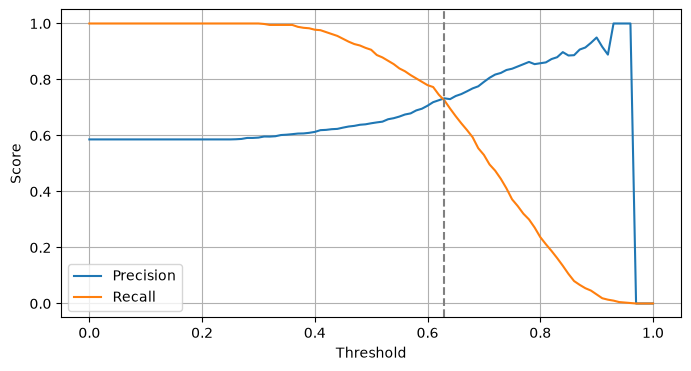

In [6]:
thresholds = np.linspace(0, 1, 101)
scores = []

for threshold in thresholds:
    converted_pred = y_pred >= threshold

    tp = ((converted_pred == 1) & (y_val == 1)).sum()
    fp = ((converted_pred == 1) & (y_val == 0)).sum()
    fn = ((converted_pred == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    scores.append((threshold, precision, recall))

df_scores = pd.DataFrame(scores, columns=["threshold", "precision", "recall"])

# Ignore thresholds where both precision and recall are zero.
nonzero_scores = df_scores[
    (df_scores["precision"] > 0) | (df_scores["recall"] > 0)
].copy()
nonzero_scores["difference"] = abs(
    nonzero_scores["precision"] - nonzero_scores["recall"]
)
intersection = nonzero_scores.loc[nonzero_scores["difference"].idxmin()]

print("Threshold with the smallest precision-recall difference:")
print(intersection)
print("Rounded threshold:")
print(round(intersection["threshold"], 2))

plt.figure(figsize=(8, 4))
plt.plot(df_scores["threshold"], df_scores["precision"], label="Precision")
plt.plot(df_scores["threshold"], df_scores["recall"], label="Recall")
plt.axvline(intersection["threshold"], color="gray", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

# At 0.63, precision is about 0.733 and recall is about 0.725.
# This is the smallest difference on the threshold grid.
# Answer: 0.63


Q4. F1 score

Threshold with the highest F1:
threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64
Rounded threshold:
0.41


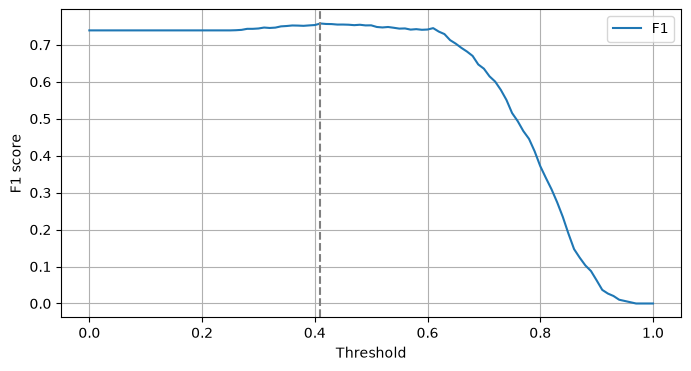

In [7]:
df_scores["f1"] = (
    2 * df_scores["precision"] * df_scores["recall"]
    / (df_scores["precision"] + df_scores["recall"])
).fillna(0.0)

best_f1 = df_scores.loc[df_scores["f1"].idxmax()]
print("Threshold with the highest F1:")
print(best_f1)
print("Rounded threshold:")
print(round(best_f1["threshold"], 2))

plt.figure(figsize=(8, 4))
plt.plot(df_scores["threshold"], df_scores["f1"], label="F1")
plt.axvline(best_f1["threshold"], color="gray", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.legend()
plt.grid()
plt.show()

# The highest F1 is about 0.758 at threshold 0.41.
# Answer: 0.41


Q5. 5-Fold cross-validation

In [8]:
def train(df_train, C=1.0):
    train_dicts = df_train[features].to_dict(orient="records")
    y_train = df_train["converted"].values

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[features].to_dict(orient="records")
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]


def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        y_val_fold = df_val_fold["converted"].values

        dv_fold, model_fold = train(df_train_fold, C=C)
        y_pred_fold = predict(df_val_fold, dv_fold, model_fold)
        score = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(score)

    return scores


cv_scores = cross_validate(C=1.0)
print("Fold and validation AUC:")
for fold, score in enumerate(cv_scores, start=1):
    print(fold, score)

# Calculate std from the scores before rounding.
score_std = np.std(cv_scores)
print("Mean AUC:")
print(np.mean(cv_scores))
print("Standard deviation of AUC scores:")
print(score_std)
print("Rounded standard deviation:")
print(round(score_std, 3))

# Standard deviation is about 0.006853 before rounding.
# Answer: 0.007


Fold and validation AUC:
1 0.7305601027122453
2 0.7295726148196622
3 0.7363428071259397
4 0.7412454717957564
5 0.7209138590326581
Mean AUC:
0.7317269710972524
Standard deviation of AUC scores:
0.006853233151022138
Rounded standard deviation:
0.007


Q6. Hyperparameter tuning

In [9]:
c_scores = []

for C in [0.000001, 0.001, 1]:
    # Reuse the C=1 scores from Q5.
    scores = cv_scores if C == 1 else cross_validate(C=C)
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    c_scores.append((C, round(mean_auc, 3), round(std_auc, 3)))

cv_results = pd.DataFrame(c_scores, columns=["C", "mean_auc", "std_auc"])
print("C, mean AUC and standard deviation:")
print(cv_results)

# Compare rounded scores: highest mean, lowest std, then smallest C.
best_c = min(c_scores, key=lambda result: (-result[1], result[2], result[0]))[0]
print("Best C:")
print(best_c)

# The best mean AUC is 0.749 with C = 0.001.
# Answer: 0.001


C, mean AUC and standard deviation:
          C  mean_auc  std_auc
0  0.000001     0.617    0.019
1  0.001000     0.749    0.010
2  1.000000     0.732    0.007
Best C:
0.001
